# **Лабораторная №2 — Сегментация изображений и выделение границ с использованием OpenCV**


# Цель работы
Получить навыки использования классических операторов выделения границ и сегментации изображений с применением библиотеки OpenCV.

In [103]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

# Теоретические сведения



Обработка изображений и компьютерное зрение являются важнейшими направлениями в области современных информационных технологий, робототехники, медицинской диагностики, геоинформационных систем, промышленного контроля качества и различных систем искусственного интеллекта. Одной из ключевых задач компьютерного зрения является **сегментация изображений**, которая представляет собой процесс разделения изображения на части, обладающие определёнными общими свойствами. Как правило, сегментация применяется для выделения объектов интереса или определённых структур изображения для последующего анализа, классификации, измерений или принятия решений.




## Понятие цифрового изображения

Цифровое изображение представляет собой двумерную дискретную функцию:

$$
F(x, y) = f_{ij}
$$

где каждому элементу (пикселю) ставится в соответствие некоторое числовое значение.  
Как правило, изображение представляется в виде матрицы:

$$
F = \begin{bmatrix}
f_{00} & f_{01} & \dots & f_{0,N-1} \\
f_{10} & f_{11} & \dots & f_{1,N-1} \\
\vdots & \vdots & \ddots & \vdots \\
f_{M-1,0} & f_{M-1,1} & \dots & f_{M-1,N-1}
\end{bmatrix}
$$

Для **полутонового изображения** каждый пиксель имеет значение интенсивности в диапазоне [0, 255], где 0 - чёрный, 255 - белый.

Для **цветных изображений** каждый пиксель задаётся вектором:

$$
f_{ij} = (R, G, B)
$$

где компоненты соответствуют интенсивностям красного, зелёного и синего каналов.


**Сегментация изображения** — это процесс разбиения исходного изображения на непересекающиеся области, обладающие однородными признаками. Обозначим множество таких областей:

$$
S = \{S_1, S_2, ..., S_n\}
$$

где выполняются условия:

$$
\bigcup_{k=1}^{n} S_k = F
$$


$$
S_i \cap S_j = \varnothing \quad \text{при } i \ne j
$$

Цель сегментации — выделить семантически значимые области изображения (например, органы, детали, текстовые элементы, дорожную разметку, дефекты и т.д.).
## Теория выделения границ (Edge Detection)
Граница изображения определяется как область, где происходит **резкое изменение яркости или цветовых компонент**. Математически обнаружение границ основано на анализе **производных функции яркости**.

Если изображение рассматривать как двумерную функцию интенсивности $$I(x, y)$$, то скорость изменения яркости по координатам описывается частными производными:

$$
\frac{\partial I}{\partial x}, \quad \frac{\partial I}{\partial y}
$$

На их основе формируется **градиент изображения**:

$$
\vec{G} = \left( \frac{\partial I}{\partial x}, \frac{\partial I}{\partial y} \right)
$$

а **модуль градиента**, показывающий степень выраженности границы, определяется как:

$$
|G| = \sqrt{\left(\frac{\partial I}{\partial x}\right)^2 + \left(\frac{\partial I}{\partial y}\right)^2}
$$

Чем больше значение модуля градиента, тем выше вероятность наличия границы. Если анализ используется через вторую производную, то границы соответствуют **нулевым переходам лапласиана**:

$$
\nabla^2 I = \frac{\partial^2 I}{\partial x^2} + \frac{\partial^2 I}{\partial y^2}
$$




## Классические операторы выделения границ

### 1. Оператор Робертса

Использует два небольших ядра свёртки (2x2), аппроксимирующих первую производную:

$$
G_x = \begin{bmatrix} 1 & 0 \\ 0 & -1 \end{bmatrix}, \quad
G_y = \begin{bmatrix} 0 & 1 \\ -1 & 0 \end{bmatrix}
$$

**Преимущества:** высокая скорость.  
**Недостатки:** низкая устойчивость к шуму, не подходит для изображений низкого качества.


### 2. Оператор Превитта

$$
G_x = \begin{bmatrix} -1 & 0 & 1 \\ -1 & 0 & 1 \\ -1 & 0 & 1 \end{bmatrix},\quad
G_y = \begin{bmatrix} 1 & 1 & 1 \\ 0 & 0 & 0 \\ -1 & -1 & -1 \end{bmatrix}
$$

Добавляет сглаживание, что улучшает устойчивость к шуму.



### 3. Оператор Собеля

$$
G_x = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix},\quad
G_y = \begin{bmatrix} 1 & 2 & 1 \\ 0 & 0 & 0 \\ -1 & -2 & -1 \end{bmatrix}
$$

Оператор Собеля является стандартом благодаря устойчивости к шуму.



### 4. Лапласиан и Laplacian of Gaussian (LoG)

Оператор Лапласа основывается на **второй производной**, выполняет поиск точек с нулевым пересечением:

$$
\nabla^2 f = \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2}
$$

Для устранения шума используется предварительное сглаживание:

$$
LoG(x,y) = -\frac{1}{\pi\sigma^4} \left(1 - \frac{x^2 + y^2}{2\sigma^2}\right) e^{-(x^2+y^2)/2\sigma^2}
$$



### 5. Алгоритм Кэнни (Canny)

Метод включает пять этапов:

1. Сглаживание изображения с помощью фильтра Гаусса.
2. Вычисление градиента с помощью оператора Собеля.
3. Подавление немаксимальных значений (Non-Maximum Suppression).
4. Двойное пороговое преобразование.
5. Гистерезис трассировки границ.




##  Дополнительные методы сегментации

### Fuzzy Logic (нечёткая логика)

Вводится степень принадлежности пикселя к границе:

$$
\mu(x) \in [0,1]
$$

Позволяет учитывать неопределённость и шумовые искажения.



### Вейвлетные методы

Вейвлет-преобразование позволяет анализировать изображение на нескольких масштабах, выделяя локальные особенности и текстуры.



### Клеточный автомат TFNCA

Метод основан на правилах преобразования пикселей в окрестности 5×5, что обеспечивает устойчивость к шумам и упрощает реализацию.



###  Преобразование Хафа

Используется для выделения параметрически описываемых объектов (линий, окружностей).  

### Теория детектирования ключевых точек

Если границы описывают **форму объекта**, то ключевые точки описывают **его уникальные локальные особенности**, позволяющие находить соответствия между изображениями, выполненными при различных условиях. Хорошая ключевая точка должна быть устойчива к изменениям масштаба, поворота, освещённости, зашумлённости и перспективным искажениям. Для её описания формируется так называемый **дескриптор признака** — числовой вектор, который можно сравнивать с аналогичными дескрипторами с помощью метрик расстояния.

Первым мощным методом, удовлетворяющим этим требованиям, стал **SIFT (Scale-Invariant Feature Transform)**. Его ключевая идея состоит в построении **масштабного пространства**, то есть набора изображений, размытых гауссовыми фильтрами с разными значениями σ; далее последовательно сравниваются разности размытия (DoG), и среди них выбираются локальные экстремумы, что позволяет находить признаки, сохраняющиеся при изменении масштаба. Дескриптор SIFT основан на распределении локальных градиентов вокруг точки и обеспечивает устойчивость к поворотам и изменению яркости.

В дальнейшем появился **SURF (Speeded-Up Robust Features)**, целью которого было ускорить вычисления. В нём используется приближённое свёрточное вычисление через **интегральные изображения и прямоугольные фильтры**, что снижает вычислительную сложность при сохранении устойчивости дескрипторов.

Переход к бинарным дескрипторам привёл к появлению **ORB**, **BRISK** и **AKAZE**. ORB сочетает детектор **FAST** и дескриптор **rBRIEF**, который представляет локальные паттерны в виде битовых последовательностей, что позволяет производить сопоставление существенно быстрее (Hamming distance). BRISK реализует более сложную и многоуровневую схему отбора локальных шаблонов, обеспечивая улучшенную масштабную устойчивость. Наиболее продвинутым считается **AKAZE**, где используется нелинейное масштабное пространство, основанное на **диффузионных уравнениях**, что делает его превосходящим SIFT и SURF на изображениях с размытием и слабым контрастом.




### Загрузка изображений с реального датасета (для задания 1)

Cloning BSDS500...

 Selected images:
 • BSDS500_clone/BSDS500/data/images/val/123074.jpg
 • BSDS500_clone/BSDS500/data/images/val/69040.jpg
 • BSDS500_clone/BSDS500/data/images/val/16077.jpg

 Saved to: data_dir


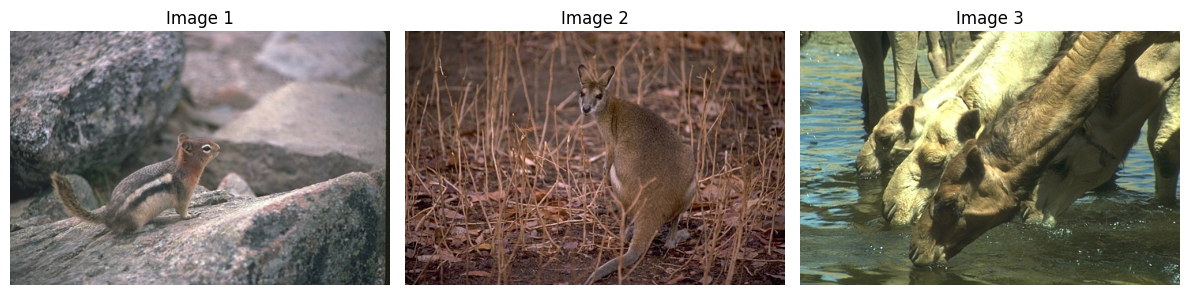

In [5]:
import os
import git
import random
import cv2
import shutil
import matplotlib.pyplot as plt


REPO_URL = "https://github.com/BIDS/BSDS500.git"
ROOT_DIR = "data_dir"
os.makedirs(ROOT_DIR, exist_ok=True)
CLONE_PATH = "BSDS500_clone"

if not os.path.exists(CLONE_PATH):
    print("Cloning BSDS500...")
    git.Repo.clone_from(REPO_URL, CLONE_PATH)
else:
    print("Already cloned")


img_paths = []
imgs_root = os.path.join(CLONE_PATH, "BSDS500", "data", "images")

for root, dirs, files in os.walk(imgs_root):
    for f in files:
        if f.lower().endswith((".jpg", ".png")):
            img_paths.append(os.path.join(root, f))


selected = random.sample(img_paths, 3)

print("\n Selected images:")
for p in selected:
    print(" •", p)

local_paths = []
for src in selected:
    filename = os.path.basename(src)
    dst = os.path.join(ROOT_DIR, filename)
    shutil.copy(src, dst)
    local_paths.append(dst)

print("\n Saved to:", ROOT_DIR)



plt.figure(figsize=(12,4))
for i, path in enumerate(local_paths):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.subplot(1,3,i+1)
    plt.imshow(img)
    plt.title(f"Image {i+1}")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [4]:
#!pip install git
!pip install GitPython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [GitPython]


# Задания к лабораторной работе

## 1. Общие правила для всех вариантов

**Дано:** сгенерируйте или подберите **3 изображения различной сложности**:  
— неоднородное освещение, текстуры и тени,  
— шумы (Gaussian, Impulse, Speckle ),  
— объекты со сложной геометрией (отверстия, тонкие детали, закругления).  

**Примечание**  В случае отсутствия собственных изображений или с целью стандартизации входных данных допускается использование автоматической выборки. Для этого достаточно выполнить предоставленный фрагмент Python-кода, который осуществляет загрузку исходного датасета, случайный выбор трёх изображений, их копирование и сохранение в директорию data_dir/. Полученные изображения разрешается использовать в дальнейшем при выполнении всех этапов лабораторной работы.

**Задача:** выполнить цепочку преобразований **строго согласно своему варианту**, исследовать влияние параметров операторов выделения границ и детектирования ключевых точек, привести визуальный и аналитический сравнительный вывод.

**Описание функций OpenCV4.5.5 и сопутствующих инструментов представлено в ПРИЛОЖЕНИИ 1.**

**На каждом изображении обязательно подписать:**  
*название оператора/метода + используемые параметры + фамилия.*


**Реализовать следующие операции обработки изображений**

## Реализовать следующие операции обработки изображений (варианты с параметрами)

**Вариант 1**  Кадрирование → Sobel (`ksize = {1, 3, 5, 7}`) vs Roberts (`cv.filter2D`, фиксированное ядро) → ORB (`nfeatures = {200, 500, 800}`).  
Показать влияние размера ядра Sobel на толщину и разрывность границ; сравнить шумоустойчивость Робертса; оценить долю ORB-keypoints, попадающих на границы.

**Вариант 2**  Поворот (`angle = ±15°, ±25°, ±35°`) → Prewitt (`axis={X, Y, Diagonal}`) vs Canny (`threshold pairs={30/90, 50/150, 80/200}`) → SIFT (`contrastThreshold={0.01, 0.03}`)  
Исследовать изменение свойств границ при наклоне; построить гистограмму направлений градиента или сравнить ориентации SIFT-keypoints.

**Вариант 3** Масштабирование (`scale = {0.5, 0.75, 1.5, 2.0}`) → LoG (`σ = {0.5, 1.0, 2.0, 3.0}`) vs Sobel (`ksize=3`) → AKAZE (`descriptor_type={MLDB, KAZE}`)  Показать, как масштаб влияет на детализацию; оценить стабильность локализации AKAZE-keypoints при росте σ.

**Вариант 4**  Unsharp (`amount = {0.5, 1.0, 1.5}`) → Roberts vs Canny (`threshold pairs={20/80, 40/120, 60/180}`) → BRISK (`thresh={20, 40, 60}`)  
Сравнить усиление деталей после Sharpen; определить, какой оператор лучше выявляет микротекстуру; оценить изменение количества ключевых точек.

**Вариант 5**  Контраст (`alpha = {0.7, 1.0, 1.5, 2.0}`, `beta={0, 20, 40}`) → Sobel (`ksize=3`) vs LoG (`σ={0.8, 1.5, 2.0}`) → SURF (`hessianThreshold={300, 500, 800}`)  Построить график зависимости «кол-во keypoints / выразительность границ» от alpha; объяснить усиление/подавление LoG.

**Вариант 6**  CLAHE (`clipLimit = {1.0, 2.0, 3.0}`, `tileGrid={4×4, 8×8}`) → Canny (`threshold pairs={40/120, 60/180}`) vs LoG (`σ={1.0, 2.0}`) → ORB (`nlevels={4, 8}`)  Оценить устойчивость оператора при локальной перераспределённой яркости; сравнить ORB-keypoints в областях засветки и теней.

**Вариант 7**  Top-Hat (`kernel = {3×3, 5×5, 7×7}`) → Prewitt (`axis={X, Y}`) → Wavelet (`db2/db4` уровни `{1,2}`) → SIFT (`contrastThreshold={0.01, 0.02}`)  
Показать, как Top-Hat подавляет фоновые текстуры; оценить ложные границы wavelet-метода.

**Вариант 8**  Bilateral (`d={5,9,13}`, `σColor={50,80}`, `σSpace={50,80}`) → Sobel (`ksize=5`) → TFNCA (`iterations={1,2,3}`, `T={10,15,20}`) → AKAZE (`descriptor_size={32,64}`)  Показать изменение гладкости и разрывов границ; оценить заполненность контуров после TFNCA.

**Вариант 9**  Добавление шума (`Gaussian σ={5,10,15}` или `S&P prob={0.01,0.03,0.05}`) → Canny (`threshold pairs={30/90, 60/140, 100/200}`) vs Sobel (`ksize=3`) → BRISK (`octaves={1,3}`) Построить таблицу деградации: шум → границы → keypoints; определить критические уровни.

**Вариант 10** Median (`kernel = {3, 5, 7}`) → LoG (`σ={0.6,1.0,1.6}`) vs Prewitt (`axis={X,Y}`) → ORB (`nfeatures={300,600,900}`)  Оценить, как фильтрация «соль/перец» влияет на сохранность геометрии контуров и локализацию ORB.

**Вариант 11**  Normalization + Gamma (`γ={0.5,0.8,1.2,1.8}`) → Roberts → TFNCA (`iterations={1,2,3}`) → SIFT (`contrastThreshold={0.01,0.03}`) Оценить влияние гамма-коррекции на восстановление структуры и устойчивость SIFT-контуров после CA.

**Вариант 12**  CLAHE (`clipLimit={1.5,2.5}`) + Bilateral (`d=9`) → Canny (`threshold pairs={20/60,50/150}`) → Fuzzy Edge Detection (`membership={sigmoid,linear}`) → AKAZE (`threshold={0.0005,0.001}`)  Сравнить классическое и нечёткое выделение границ; определить где распределение AKAZE является наиболее информативным.


----

## 2. Выполнить выделение объектов на бинарном изображении (сегментированном ранее в Задании №1)  
и **вычислить свойства каждого найденного объекта**, включая **не менее четырёх** из приведённых ниже:

- площадь (`area`)
- периметр (`perimeter`)
- компактность (`4π * Area / Perimeter²`)
- округлость
- аспектное отношение (`width / height`)
- заполненность (`Area / BoundingBoxArea`)
- эксцентриситет (через моменты)

**Описание сопутствующего математического аппарата представлено в ПРИЛОЖЕНИИ 2**.

Результат выполнения:

* кратко описать условия получения изображений (освещение, фон, ракурс, шумы, тип объектов, наличие перекрытий);
* оценить **корректность сегментации и выделения объектов**: полнота (все ли объекты найдены), отсутствие ложных областей, корректность разделения слипшихся объектов;
* оценить **адекватность вычисленных метрик**: соответствие геометрическим свойствам объектов (например, круглые → высокая компактность, вытянутые → аспектное отношение >> 1);
* указать проблемные случаи и возможные причины (тени, низкий контраст, текстуры, неравномерная подсветка, частичное перекрытие, артефакты бинаризации, сглаживание контуров);
* предложить способы улучшения (другая предобработка, CLAHE, изменение порога, морфология, выделение по цвету, смена пространства, фильтрация шума);
* приложить **2–3 показательных примера «хорошо/плохо»** с визуализацией и кратким пояснением, что именно пошло не так или, наоборот, почему результат является корректным.

----

##Содержание отчета

1.	Титульный лист.  
2.	Цель лабораторной работы.
3.	Ход работы с пояснениями алгоритмов из первого задания, примерами обработки по заданиям и их анализом.
4.	Результаты выполнения второго пункта задания.
5.	Листинг кода.
6.	Выводы о проделанной работе.



## ПРИЛОЖЕНИЕ 1. Описание используемых функций OpenCV

`cv.imread` / `cv.imwrite` — загрузка и сохранение изображений  
`cv.imshow` / `cv.waitKey` — отображение результатов  

`cv.resize` (`INTER_NEAREST`, `INTER_LINEAR`, `INTER_CUBIC`, `INTER_AREA`, `INTER_LANCZOS4`) — масштабирование изображения  
`cv.flip` — зеркальное отражение (по оси X/Y)

`cv.cvtColor` — преобразование цветовых пространств (`GRAYSCALE`, `HSV`, `LAB`)  
`cv.GaussianBlur`, `cv.medianBlur`, `cv.bilateralFilter` — сглаживание и подавление шума  
`cv.createCLAHE` (`clipLimit`, `tileGridSize`) — локальное повышение контраста


### Операторы выделения границ

`cv.Sobel` — градиентные производные по X/Y (`ksize = 1 / 3 / 5 / 7`)  
`cv.Canny` — детектор границ (нижний/верхний пороги)  
`cv.Laplacian` / `LoG` — вторые производные (усиление границ)  
*(custom kernels via `cv.filter2D`) — `Roberts`, `Prewitt`*  




### Ключевые точки и дескрипторы

`cv.SIFT_create`, `cv.BRISK_create`, `cv.ORB_create`, `cv.AKAZE_create`  
`detector.detectAndCompute(img, mask=None)` — извлечение keypoints и дескрипторов  
`cv.drawKeypoints` — визуализация найденных ключевых точек



### Бинаризация и сегментация

`cv.threshold` (`BINARY`, `BINARY_INV`, `OTSU`) — глобальное пороговое разделение  
`cv.inRange` — цветовая сегментация (HSV / Lab диапазоны)



###  Контуры и компоненты

`cv.findContours` — поиск контуров (`RETR_EXTERNAL`, `CHAIN_APPROX_SIMPLE`)  
`cv.contourArea` — вычисление площади объекта  
`cv.arcLength` — вычисление периметра  
`cv.boundingRect` — ограничивающий прямоугольник (`width / height`)  
`cv.convexHull` — выпуклая оболочка объекта (для заполненности)  
`cv.fitEllipse` — эллиптическая аппроксимация (эксцентриситет)  
`cv.connectedComponents` — маркировка связных компонент (метки)


## ПРИЛОЖЕНИЕ 2. Математические формулы, используемые в работе



**Градиентные производные:**

$$
G_x = \frac{dI}{dx},\quad G_y = \frac{dI}{dy}
$$

**Модуль градиента:**
$$
|G| = \sqrt{G_x^2 + G_y^2}
$$

**Оператор Лапласа:**

$$
\nabla^2 I = \frac{d^2I}{dx^2} + \frac{d^2I}{dy^2}
$$

**Оператор LoG (Laplacian of Gaussian):**

$$
LoG = \nabla^2 (G * I)
$$


### Метрики форм объектов

**Площадь:**

$$
Area = \text{количество пикселей внутри контура}
$$

**Периметр:**

$$
Perimeter = \text{длина внешнего контура объекта}
$$

**Аспектное отношение:**

$$
AR = \frac{Width}{Height}
$$

**Компактность (округлость):**

$$
Compactness = \frac{4\pi \cdot Area}{Perimeter^2}
$$

**Заполненность (solidity):**

$$
Solidity = \frac{Area}{Area_{convex\_hull}}
$$

**Bounding-box заполненность (упрощённый вариант):**

$$
Fill = \frac{Area}{Width \cdot Height}
$$

**Эксцентриситет (по параметрам эллипса):**
$$
Eccentricity = \sqrt{1 - \frac{b^2}{a^2}}
$$

где  
*`a` — большая полуось, `b` — малая полуось*



**На каждом изображении обязательно подписать:**  
*название оператора/метода + используемые параметры + фамилия.*

**Вариант 2**  
Поворот (`angle = ±15°, ±25°, ±35°`) → Prewitt (`axis={X, Y, Diagonal}`) vs Canny (`threshold pairs={30/90, 50/150, 80/200}`) → SIFT (`contrastThreshold={0.01, 0.03}`)  
Исследовать изменение свойств границ при наклоне; построить гистограмму направлений градиента или сравнить ориентации SIFT-keypoints.

In [90]:
images=[]
for i, path in enumerate(local_paths):
  img_ = cv2.imread(path)
  img_ = cv2.cvtColor(img_, cv2.COLOR_BGR2RGB)
  height, width = img.shape[:2]
  center = (width // 2, height // 2)
  images.append(img_)

In [ ]:

for angle in [-35, -25, -15, 15, 25, 35]:
    plt.figure(figsize=(12,4))
    for i in range(3):
        img = images[i]

        #https://opencv.org/image-rotation-and-translation-using-opencv/
        height, width = img.shape[:2]
        center = (width // 2, height // 2)
        #angle = 15
        scale = 1.0
        rotation_matrix = cv2.getRotationMatrix2D(center, angle, scale)
        img = cv2.warpAffine(img, rotation_matrix, (width, height))

        plt.subplot(1,3,i+1)
        plt.imshow(img)
        plt.title(f"Image {i+1} rotated at angle {angle} (Баранова)")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:
for angle in [-35, -25, -15, 15, 25, 35]:
    plt.figure(figsize=(12,4))
    for i in range(3):
        img = images[i]
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        #https://opencv.org/image-rotation-and-translation-using-opencv/
        rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
        img = cv2.warpAffine(img, rotation_matrix, (width, height))

        #https://opencv.org/edge-detection-using-opencv/#h-canny-edge-detector
        #img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        blur = cv2.GaussianBlur(img, (5, 5), 1.4)
        edges = cv2.Canny(blur, threshold1=30, threshold2=90)
        #cv2.imshow("Canny Edge Detection", edges)

        plt.subplot(1,3,i+1)
        plt.imshow(edges)
        plt.title(f"Canny edges (30/90) of image {i+1}\nrotated at angle {angle} (Баранова)")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:
for angle in [-35, -25, -15, 15, 25, 35]:
    plt.figure(figsize=(12,4))
    for i in range(3):
        img = images[i]
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        #https://opencv.org/image-rotation-and-translation-using-opencv/
        rotation_matrix = cv2.getRotationMatrix2D(center, angle, scale)
        img = cv2.warpAffine(img, rotation_matrix, (width, height))

        #https://opencv.org/edge-detection-using-opencv/#h-canny-edge-detector
        #img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        blur = cv2.GaussianBlur(img, (5, 5), 1.4)
        edges = cv2.Canny(blur, threshold1=50, threshold2=150)
        #cv2.imshow("Canny Edge Detection", edges)

        plt.subplot(1,3,i+1)
        plt.imshow(edges)
        plt.title(f"Canny edges (50/150) of image {i+1}\nrotated at angle {angle} (Баранова)")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:


for angle in [-35, -25, -15, 15, 25, 35]:
    plt.figure(figsize=(12,4))
    for i in range(3):
      img = images[i]
      img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
      #https://opencv.org/image-rotation-and-translation-using-opencv/
      rotation_matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
      img = cv2.warpAffine(img, rotation_matrix, (width, height))

      #https://opencv.org/edge-detection-using-opencv/#h-canny-edge-detector
      #img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
      blur = cv2.GaussianBlur(img, (5, 5), 1.4)
      edges = cv2.Canny(blur, threshold1=80, threshold2=200)
      #cv2.imshow("Canny Edge Detection", edges)

      plt.subplot(1,3,i)
      plt.imshow(edges)
      plt.title(f"Canny edges (80/200) of image {i}\nrotated at angle {angle} (Баранова)")
      plt.axis("off")
    plt.tight_layout()
    plt.show()


In [ ]:
for angle in [-35, -25, -15, 15, 25, 35]:
    plt.figure(figsize=(12,4))
    for i in range(3):
        img = images[i]
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        #https://opencv.org/image-rotation-and-translation-using-opencv/
        height, width = img.shape[:2]
        center = (width // 2, height // 2)
        angle += 10 #angle = 15
        scale = 1.0
        rotation_matrix = cv2.getRotationMatrix2D(center, angle, scale)
        img = cv2.warpAffine(img, rotation_matrix, (width, height))

        #https://opencv.org/edge-detection-using-opencv/#h-canny-edge-detector
        #img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        blur = cv2.GaussianBlur(img, (5, 5), 1.4)
        edges = cv2.Canny(blur, threshold1=30, threshold2=90)
        #cv2.imshow("Canny Edge Detection", edges)

        #https://docs.opencv.org/4.13.0/da/df5/tutorial_py_sift_intro.html
        sift = cv2.SIFT_create()
        gray = cv2.imread(path)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        kp = sift.detect(gray,None)
        img=cv2.drawKeypoints(gray,kp,img,flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        plt.subplot(1,3,i+1)
        plt.imshow(img)
        plt.title(f"Canny edges (30/90) of image {i+1}\nrotated at angle {angle} (Баранова)")
        plt.axis("off")

    plt.tight_layout()
    plt.show()
